# Handwritten Character Recognition with Binary Image Analysis

An introductory computer vision project using thresholding, connected components, Hu moments and nearest-neighbor classification. Saved outputs are from the original course dataset.

## 1. Setup and preparation

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from sklearn.metrics import confusion_matrix
import pickle
from pathlib import Path

# Use Path("data/demo") to run with the optional synthetic dataset.
DATA_DIR = Path("data")

def read_image(filename):
    path = DATA_DIR / filename
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise FileNotFoundError(f"Missing image: {path}. See README.md for setup.")
    return image


## 2. Training phase

### 2.1 Reading and binarizing images

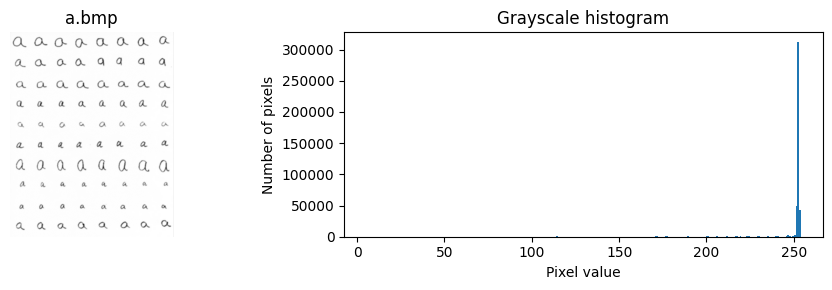

In [ ]:
img = read_image('a.bmp')

plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('a.bmp')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.hist(img.ravel(), bins=256)
plt.title('Grayscale histogram')
plt.xlabel('Pixel value')
plt.ylabel('Number of pixels')
plt.tight_layout()
plt.show()

Otsu threshold: 192.0


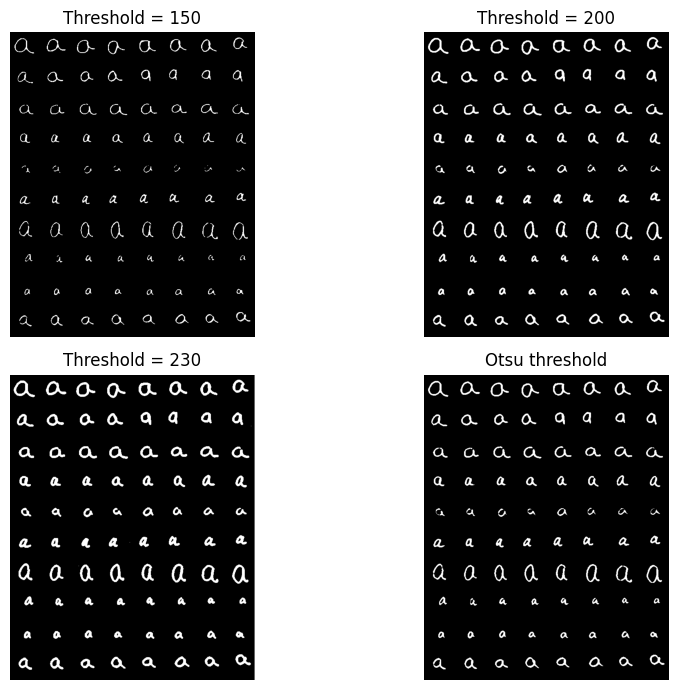

In [ ]:
_, binary150 = cv2.threshold(img, 150, 255, cv2.THRESH_BINARY_INV)
_, binary200 = cv2.threshold(img, 200, 255, cv2.THRESH_BINARY_INV)
_, binary230 = cv2.threshold(img, 230, 255, cv2.THRESH_BINARY_INV)
threshold, img_binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

print('Otsu threshold:', threshold)

plt.figure(figsize=(10, 7))
for i, (picture, title) in enumerate([
  (binary150, 'Threshold = 150'),
  (binary200, 'Threshold = 200'),
  (binary230, 'Threshold = 230'),
  (img_binary, 'Otsu threshold')
]):
  plt.subplot(2, 2, i + 1)
  plt.imshow(picture, cmap='gray')
  plt.title(title)
  plt.axis('off')
plt.tight_layout()
plt.show()

Qs:

• Explore/explain why we used THRESH_BINARY_INV and not THRESH_BINARY

• Explore and explain briefly what is Otsu algorithm

• Why “+” is used here, what is the expected behaviour: cv2.THRESH_BINARY_INV +
cv2.THRESH_OT

• Because the handwriting is dark and the background is light. When we invert  it, it makes the background black and the writing white needed for binary image analysis.

• Otus's algorithm is an algorithm that automatically chooses a threshold through separating darker and lighter pixels with the histogram.

• Using "+" allows us to use both Otsu's to determine the threshold, and binary inversion so that the background is black and writing white.

### 2.2 Connected component analysis

Detected characters in a.bmp: 80


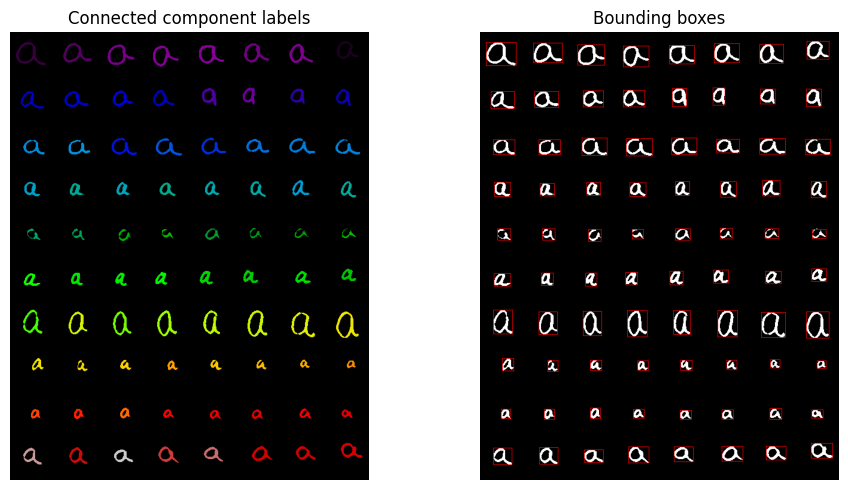

In [ ]:
num_labels, component_labels, stats, centroids = cv2.connectedComponentsWithStats(img_binary, connectivity=8)

min_area = 60
boxed = cv2.cvtColor(img_binary, cv2.COLOR_GRAY2RGB)
count = 0

for i in range(1, num_labels):
    x, y, w, h, area = stats[i]
    if area < min_area:
        continue
    cv2.rectangle(boxed, (x, y), (x + w, y + h), (255, 0, 0), 1)
    count += 1

print('Detected characters in a.bmp:', count)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(component_labels, cmap='nipy_spectral')
plt.title('Connected component labels')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(boxed)
plt.title('Bounding boxes')
plt.axis('off')
plt.tight_layout()
plt.show()

### 2.3 Feature extraction (Hu moments)

In [ ]:
for i in range(1, num_labels):
    x, y, w, h, area = stats[i]
    if area < min_area:
        continue

    roi = img_binary[y:y+h, x:x+w]
    moments = cv2.moments(roi, True)
    hu = cv2.HuMoments(moments).flatten()
    print('Example: seven Hu moments for one character:')
    print(hu)
    break

Example: seven Hu moments for one character:
[ 4.37653252e-01  4.08041684e-03  1.01513704e-02  7.26341698e-05
  5.15562022e-08  4.38629135e-06 -3.50990050e-08]


### 2.4 Building the feature database

In [ ]:
letters = ['a', 'd', 'm', 'n', 'o', 'p', 'q', 'r', 'u', 'w']
features = []
labels = []

for letter in letters:
    image = read_image(letter + '.bmp')
    _, binary = cv2.threshold(image, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    num, components, stats, centers = cv2.connectedComponentsWithStats(binary, connectivity=8)
    count = 0

    for i in range(1, num):
        x, y, w, h, area = stats[i]
        if area < min_area:
            continue

        roi = binary[y:y+h, x:x+w]
        moments = cv2.moments(roi, True)
        hu = cv2.HuMoments(moments).flatten()
        features.append(hu)
        labels.append(ord(letter))
        count += 1

    print(letter + ':', count, 'characters')

features = np.array(features)
labels = np.array(labels).reshape(-1, 1)
print('Feature matrix shape:', features.shape)
print('Label matrix shape:', labels.shape)

a: 80 characters
d: 80 characters
m: 80 characters
n: 81 characters
o: 81 characters
p: 80 characters
q: 80 characters
r: 80 characters
u: 78 characters
w: 80 characters
Feature matrix shape: (800, 7)
Label matrix shape: (800, 1)


### 2.5 Normalization

In [ ]:
mean = np.mean(features, axis=0)
std = np.std(features, axis=0)
std[std == 0] = 1
features_norm = (features - mean) / std

with open(DATA_DIR / 'training_data.pkl', 'wb') as f:
    pickle.dump((features_norm, labels, mean, std), f)

print('Saved training_data.pkl')

Saved training_data.pkl


Q: Why normalize?

The Hu moments have different ranges and by normalizing we can give each feature a similar influence when calculating the Euclidean distances.

## 3. Recognition on training data

Training accuracy: 47.62%


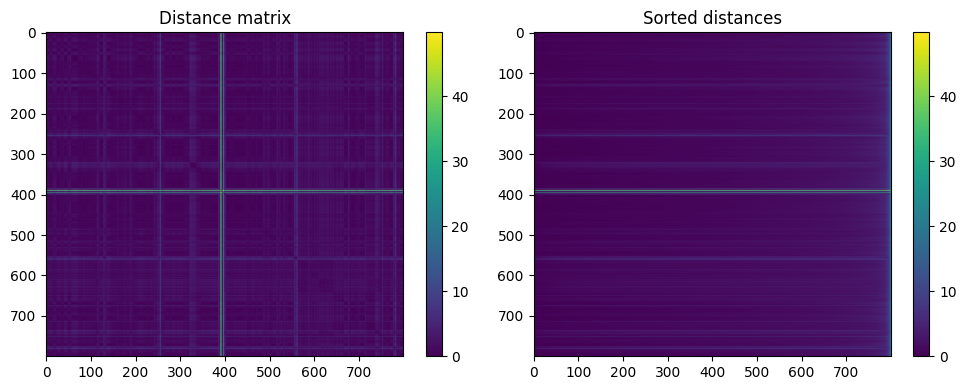

In [ ]:
D = cdist(features_norm, features_norm)
D_index = np.argsort(D, axis=1)

# Column 0 is the character itself, so use column 1.
y_true = labels[:, 0]
y_pred = y_true[D_index[:, 1]]
train_accuracy = 100 * np.mean(y_true == y_pred)
print('Training accuracy: %.2f%%' % train_accuracy)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(D, cmap='viridis', aspect='auto')
plt.title('Distance matrix')
plt.colorbar()
plt.subplot(1, 2, 2)
plt.imshow(np.sort(D, axis=1), cmap='viridis', aspect='auto')
plt.title('Sorted distances')
plt.colorbar()
plt.tight_layout()
plt.show()

### 3.2 Confusion matrix

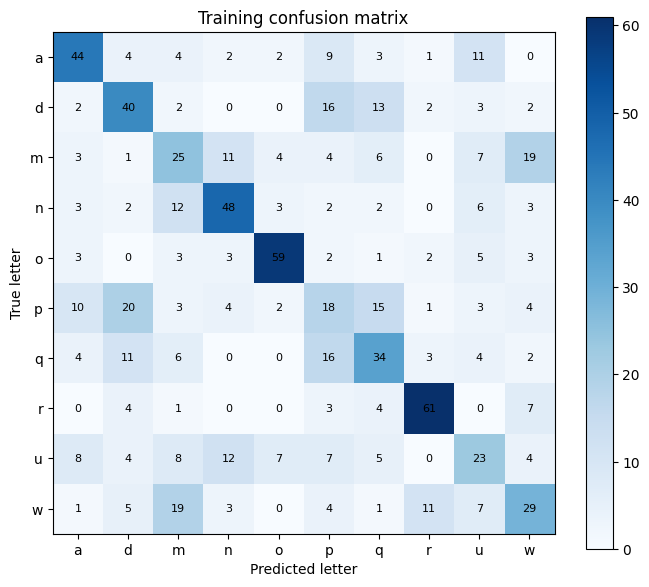

In [ ]:
letter_codes = [ord(letter) for letter in letters]
confM = confusion_matrix(y_true, y_pred, labels=letter_codes)

plt.figure(figsize=(7, 6))
plt.imshow(confM, cmap='Blues')
plt.xticks(range(len(letters)), letters)
plt.yticks(range(len(letters)), letters)
plt.xlabel('Predicted letter')
plt.ylabel('True letter')
plt.title('Training confusion matrix')
plt.colorbar()
for row in range(len(letters)):
    for col in range(len(letters)):
        plt.text(col, row, str(confM[row, col]), ha='center', va='center', fontsize=8)
plt.tight_layout()
plt.show()

## 4. Testing phase

Test Otsu threshold: 200.0
Detected test characters: 70


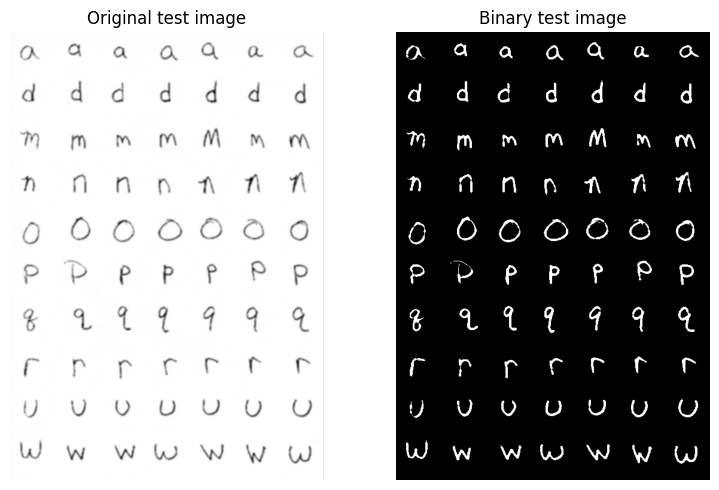

In [ ]:
# Load the held-out test image.
test_img = read_image('test.bmp')
test_threshold, test_binary = cv2.threshold(test_img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

num, components, stats, centers = cv2.connectedComponentsWithStats(test_binary, connectivity=8)
test_features = []
test_boxes = []

for i in range(1, num):
    x, y, w, h, area = stats[i]
    if area < min_area:
        continue

    roi = test_binary[y:y+h, x:x+w]
    hu = cv2.HuMoments(cv2.moments(roi, True)).flatten()
    test_features.append(hu)
    test_boxes.append((x, y, w, h, area))

test_features = np.array(test_features)
test_features_norm = (test_features - mean) / std
D_test = cdist(test_features_norm, features_norm)
nearest = np.argmin(D_test, axis=1)
test_pred = y_true[nearest]

print('Test Otsu threshold:', test_threshold)
print('Detected test characters:', len(test_boxes))

plt.figure(figsize=(8, 5))
plt.subplot(1, 2, 1)
plt.imshow(test_img, cmap='gray')
plt.title('Original test image')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(test_binary, cmap='gray')
plt.title('Binary test image')
plt.axis('off')
plt.tight_layout()
plt.show()

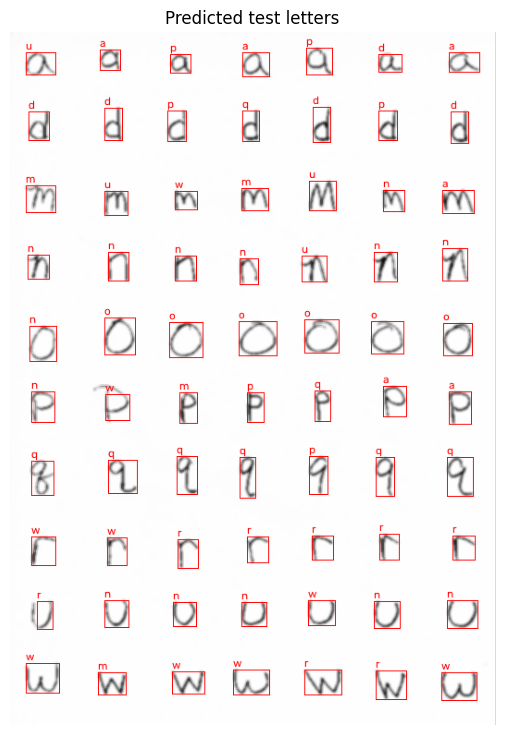

In [ ]:
predicted_image = cv2.cvtColor(test_img, cv2.COLOR_GRAY2RGB)
for (x, y, w, h, area), pred in zip(test_boxes, test_pred):
  cv2.rectangle(predicted_image, (x, y), (x+w, y+h), (255, 0, 0), 1)
  cv2.putText(predicted_image, chr(pred), (x, max(10, y-3)),
              cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 0, 0), 1)

plt.figure(figsize=(8, 9))
plt.imshow(predicted_image)
plt.title('Predicted test letters')
plt.axis('off')
plt.show()

### 4.2 Compare predictions with ground truth

Ground-truth characters: 70
Matched bounding boxes: 70
Correct predictions: 37
Test recognition rate: 52.86%


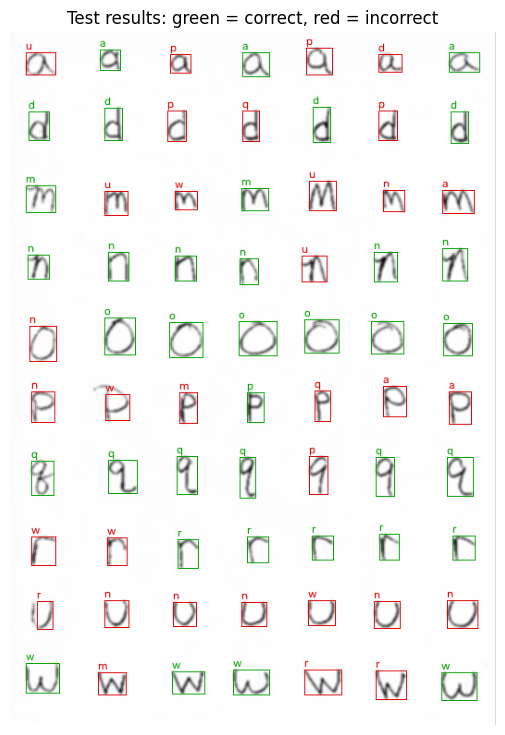

In [ ]:
with open(DATA_DIR / 'test_gt.pkl', 'rb') as f:
  gt = pickle.load(f)

classes = gt[b'classes']
locations = gt[b'locations']
correct = 0
matched = 0
result_image = cv2.cvtColor(test_img, cv2.COLOR_GRAY2RGB)

# For this particular file the coordinates are (x, y), not (row, column).
# The ground-truth letter U is uppercase, while the training filename is u.bmp.
for gt_letter, (cx, cy) in zip(classes, locations):
  for (x, y, w, h, area), pred in zip(test_boxes, test_pred):
    if x <= cx < x+w and y <= cy < y+h:
      matched += 1
      if chr(pred).lower() == str(gt_letter).lower():
        correct += 1
        color = (0, 160, 0)
      else:
        color = (220, 0, 0)
      cv2.rectangle(result_image, (x, y), (x+w, y+h), color, 1)
      cv2.putText(result_image, chr(pred), (x, max(10, y-3)),
                  cv2.FONT_HERSHEY_SIMPLEX, 0.4, color, 1)
      break

print('Ground-truth characters:', len(classes))
print('Matched bounding boxes:', matched)
print('Correct predictions:', correct)
print('Test recognition rate: %.2f%%' % (100 * correct / len(classes)))

plt.figure(figsize=(8, 9))
plt.imshow(result_image)
plt.title('Test results: green = correct, red = incorrect')
plt.axis('off')
plt.show()

Q: In the testing phase, why we normalize the feature using the mean and std of the training features and not the test features?

We need to measure test features on the same scale as the training features. If we calculate a new mean and standard deviation from the test image, the distance between test and training characters would not be comparable.